## Introduction

Hello, welcome to our kernel.
Our goal in this kernel is to predict the type of skin cancer using the deep learning algorithm. The algorithm we use is convolution neural network. And we use transfer learning.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
%matplotlib inline
from keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPool2D, MaxPooling2D
from wordcloud import WordCloud, STOPWORDS, ImageColorGenerator
from keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.preprocessing import label_binarize
from keras.utils.np_utils import to_categorical
from keras.callbacks import ReduceLROnPlateau
from sklearn.metrics import confusion_matrix
from keras.models import Sequential
import matplotlib.pyplot as plt
from keras import backend as K
import tensorflow as tf
from glob import glob
import seaborn as sns
from PIL import Image
import pandas as pd
import numpy as np
import itertools
import keras
import os


-------------------------

## Meta Data Read

In [ ]:
diagnosis = {
    'BCC': 'basal cell carcinoma',
    'NEV': 'nevus',
    'MEL': 'melanoma',
    'MISC': 'miscellaneous',
    'SK': 'seborrheic keratosis'
}

In [ ]:
base_dir = '/content/drive/MyDrive/Capstone_Project/dataset/release_v0/'
meta_dir = 'meta/'
image_dir = 'images/'


meta_df = pd.read_csv(os.path.join(base_dir, meta_dir, 'new_meta.csv'))
original_meta_df = pd.read_csv(os.path.join(base_dir, meta_dir, 'meta.csv'))

In [ ]:
original_meta_df.head()

,case_num,diagnosis,seven_point_score,pigment_network,streaks,pigmentation,regression_structures,dots_and_globules,blue_whitish_veil,vascular_structures,level_of_diagnostic_difficulty,elevation,location,sex,management,clinic,derm,case_id,notes
0,1,basal cell carcinoma,0,absent,absent,absent,absent,absent,absent,arborizing,medium,nodular,abdomen,female,excision,NEL/NEL025.JPG,NEL/Nel026.jpg,NaN,NaN
1,2,basal cell carcinoma,1,absent,absent,absent,absent,irregular,absent,absent,low,palpable,head neck,female,excision,NEL/NEL027.JPG,NEL/Nel028.jpg,NaN,NaN
2,3,basal cell carcinoma,1,absent,absent,absent,absent,irregular,absent,arborizing,medium,palpable,head neck,female,excision,NEL/Nel032.jpg,NEL/Nel033.jpg,NaN,NaN
3,4,basal cell carcinoma,4,absent,absent,absent,blue areas,irregular,present,within regression,low,palpable,lower limbs,male,excision,NEL/NEL034.JPG,NEL/Nel035.jpg,NaN,NaN
4,5,basal cell carcinoma,1,absent,absent,diffuse irregular,absent,absent,absent,absent,high,palpable,upper limbs,female,excision,NEL/NEL036.JPG,NEL/Nel037.jpg,NaN,NaN


In [ ]:
meta_df.head()

,diagnosis,clinic
0,BCC,NEL/NEL025.JPG
1,BCC,NEL/NEL027.JPG
2,BCC,NEL/Nel032.jpg
3,BCC,NEL/NEL034.JPG
4,BCC,NEL/NEL036.JPG


--------------------------

## Data Preprocessing

In [ ]:
meta_df['diag'] = meta_df['diagnosis'].map(diagnosis.get)
meta_df['diag_id'] = pd.Categorical(meta_df['diag']).codes

In [ ]:
meta_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3591 entries, 0 to 3590
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   diagnosis  3591 non-null   object
 1   clinic     3591 non-null   object
 2   diag       3591 non-null   object
 3   diag_id    3591 non-null   int8  
dtypes: int8(1), object(3)
memory usage: 87.8+ KB


In [ ]:
meta_df.isnull().sum()

diagnosis    0
clinic       0
diag         0
diag_id      0
dtype: int64

In [ ]:
meta_df = meta_df.dropna(how='any')
meta_df.isnull().sum()

diagnosis    0
clinic       0
diag         0
diag_id      0
dtype: int64

-----------------------------------

## Data Visualization

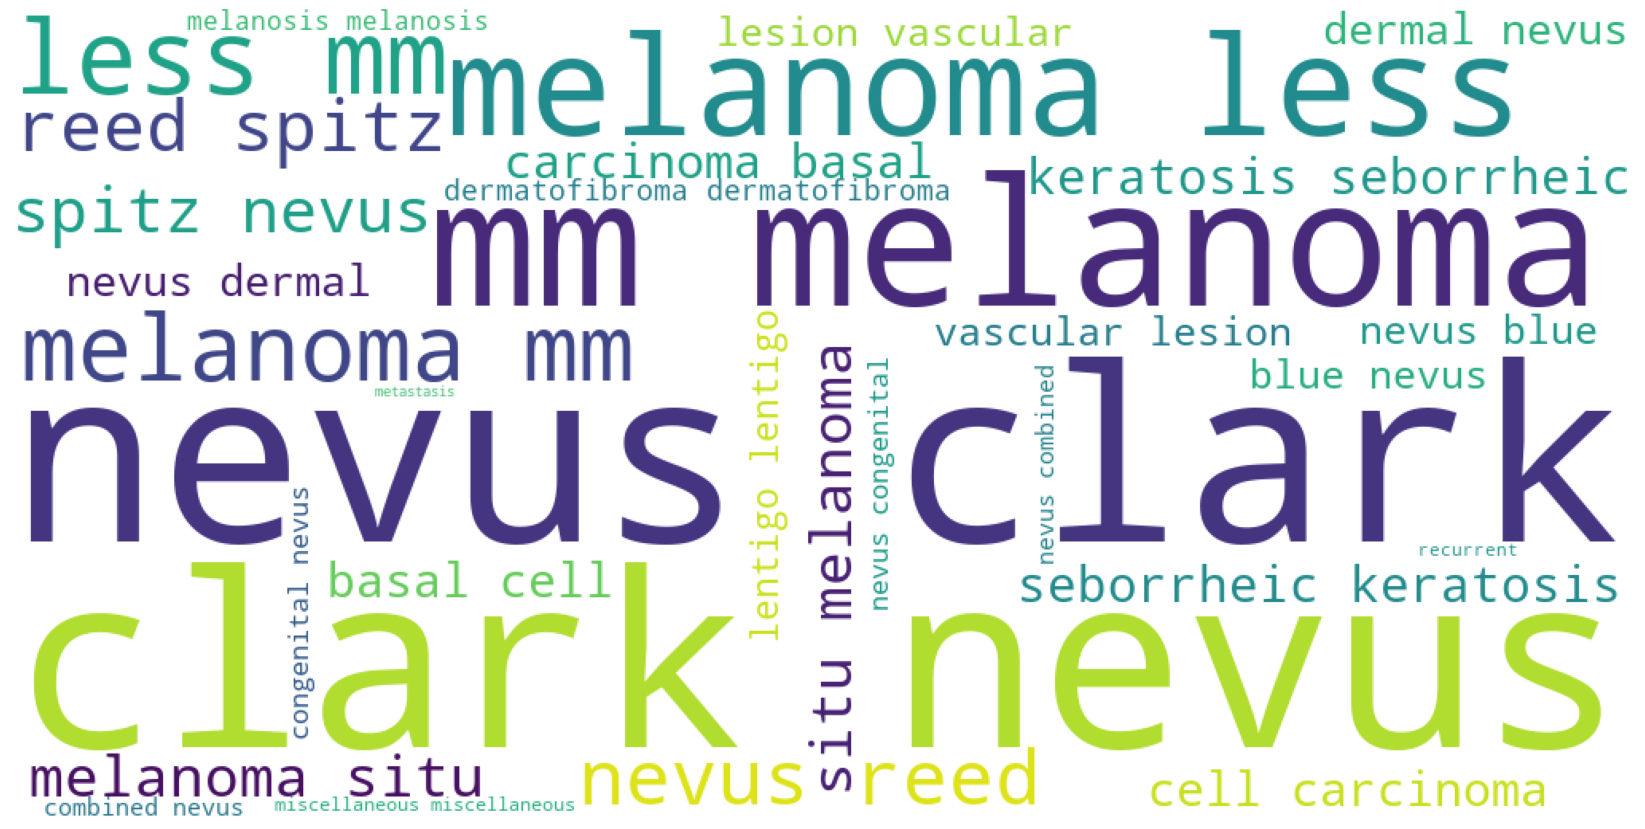

In [ ]:
data = original_meta_df.diagnosis
plt.subplots(figsize=(30,15))
wordcloud = WordCloud(background_color='white',
                      width=1024,
                      height=512
                      ).generate(" ".join(data))
plt.imshow(wordcloud)
plt.axis('off')
plt.savefig('ofiginal class names.png')

plt.show()

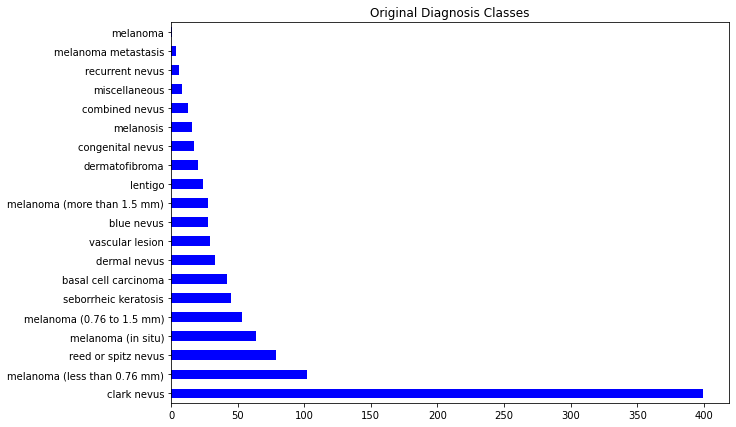

In [ ]:
fig, ax1 = plt.subplots(1, 1, figsize= (10, 7))
original_meta_df['diagnosis'].value_counts().plot(kind='barh', ax=ax1 , color="blue" )
plt.savefig('original class distibution.png')
plt.title('Original Diagnosis Classes')
plt.show()

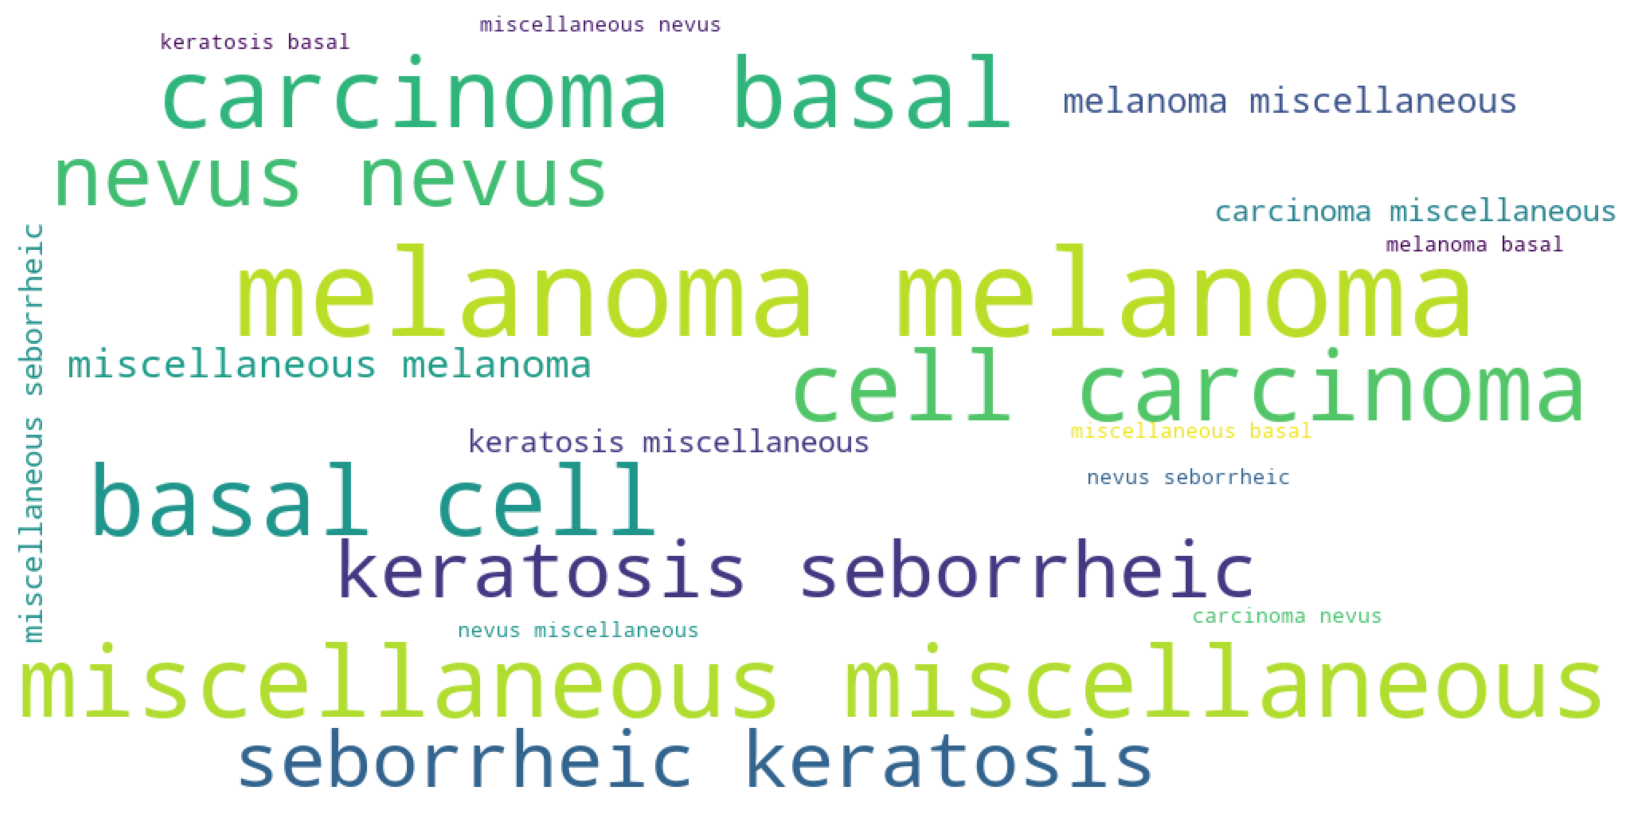

In [ ]:
data = meta_df.diag
plt.subplots(figsize=(30,15))
wordcloud = WordCloud(background_color='white',
                      width=1024,
                      height=512
                      ).generate(" ".join(data))
plt.imshow(wordcloud)
plt.axis('off')
plt.savefig('Combined class names.png')

plt.show()

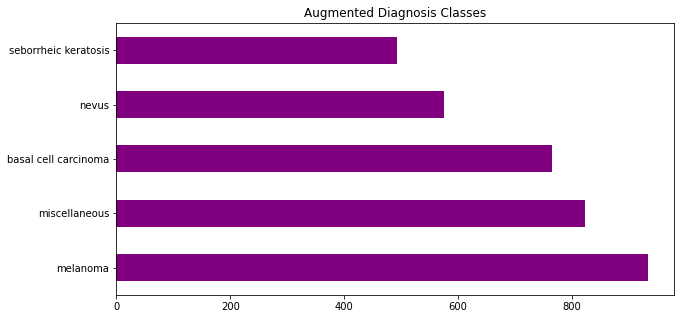

In [ ]:
fig, ax1 = plt.subplots(1, 1, figsize= (10, 5))
meta_df['diag'].value_counts().plot(kind='barh', ax=ax1 , color="purple" )
plt.savefig('New class distibution.png')
plt.title('Augmented Diagnosis Classes')
plt.show()



---



## Load images 224x224x3

In [ ]:
image_shape = 224

In [ ]:
meta_df['image'] = meta_df['clinic'].map(lambda x: np.asarray(Image.open(os.path.join(base_dir, image_dir, x)).resize((image_shape, image_shape))))

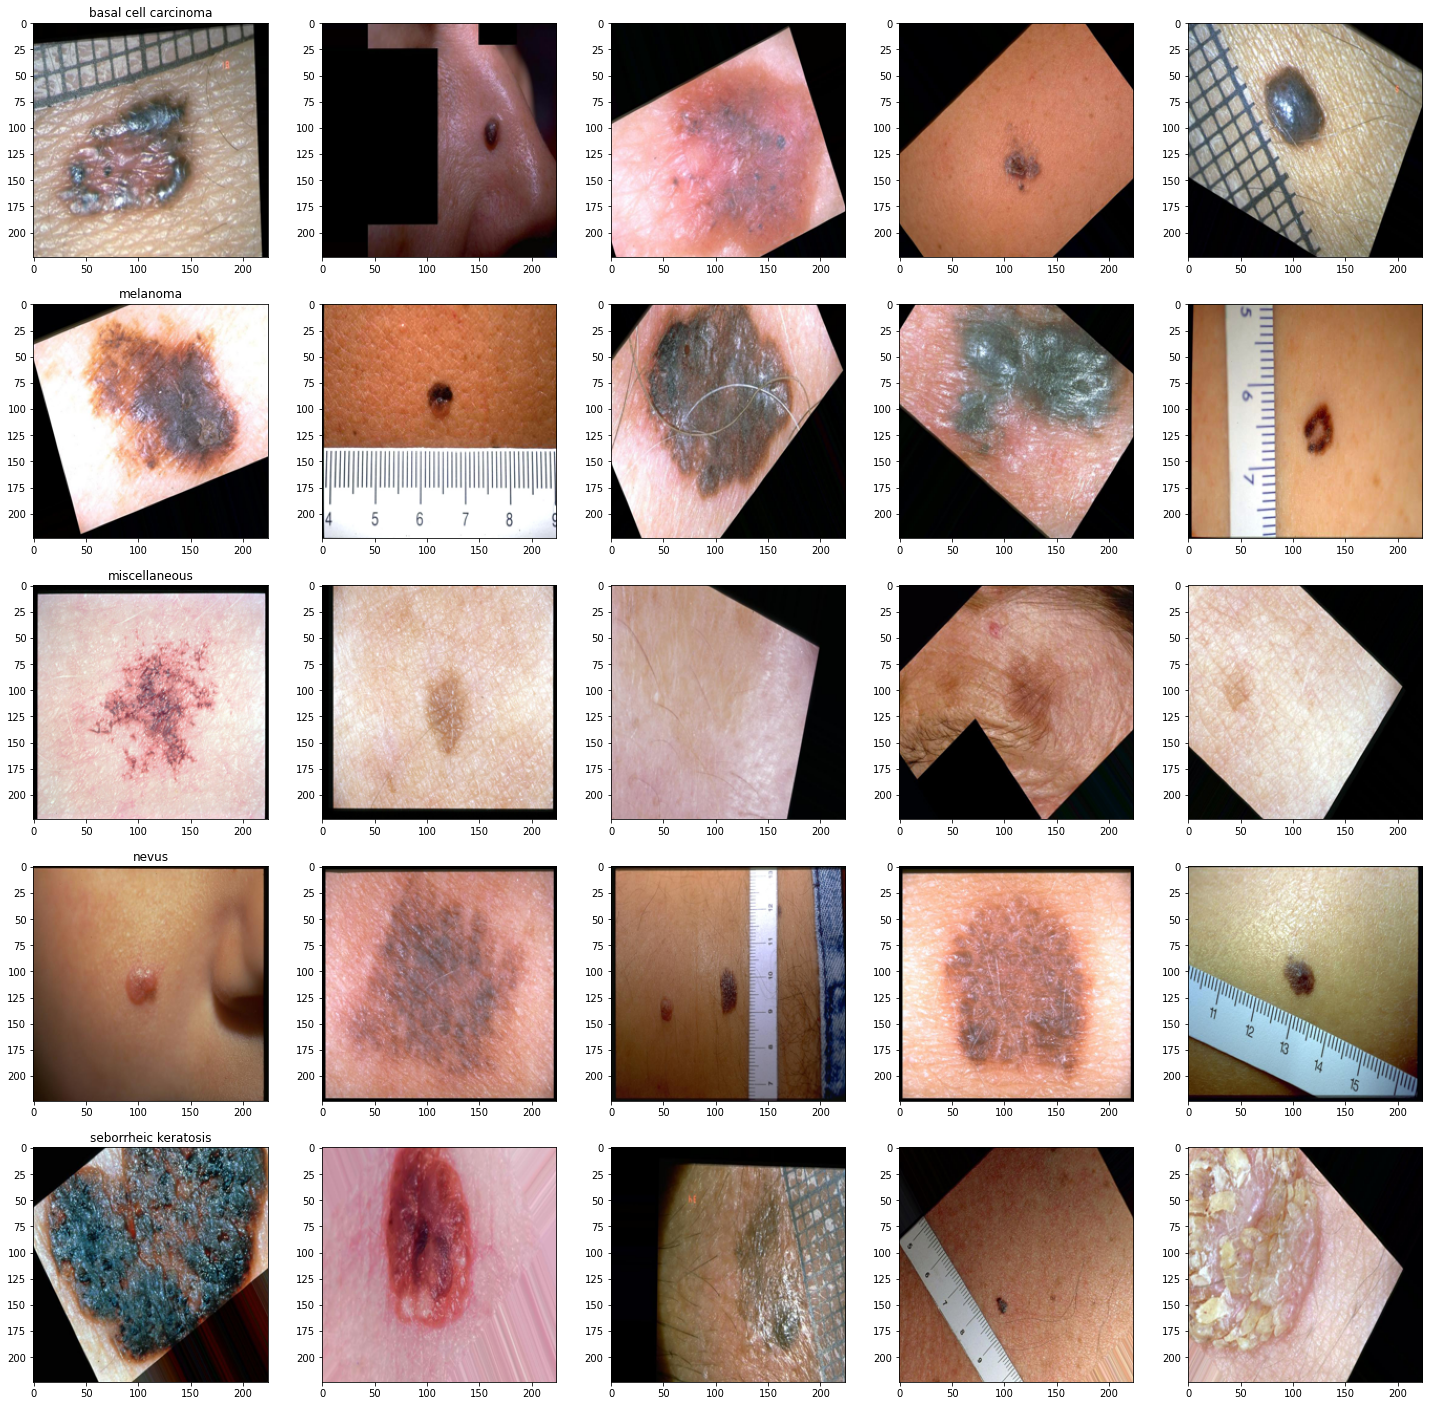

In [ ]:
n_samples = 5
fig, m_axs = plt.subplots(5, n_samples, figsize = (5*n_samples, 5*5))
for n_axs, (type_name, type_rows) in zip(m_axs,meta_df.sort_values(['diag']).groupby('diag')):
    n_axs[0].set_title(type_name)
    for c_ax, (_, c_row) in zip(n_axs, type_rows.sample(n_samples, random_state = 30).iterrows()):
        c_ax.imshow(c_row['image'])
fig.savefig('category_samples_resizd.png', dpi=300)



---



##Split data set using train_test_split()

In [ ]:
X_train = meta_df.drop(columns=['diag_id'],axis=1)
Y_train = meta_df['diag_id']

x_orjinal_train , x_orjinal_test, y_orjinal_train, y_orjinal_test = train_test_split(X_train, Y_train, test_size=0.2,random_state=55)


y_train = to_categorical(y_orjinal_train, num_classes = 5)
y_test = to_categorical(y_orjinal_test, num_classes = 5)

x_train = np.asarray(x_orjinal_train['image'].tolist())
x_test = np.asarray(x_orjinal_test['image'].tolist())

x_train_mean = np.mean(x_train)
x_train_std = np.std(x_train)

x_test_mean = np.mean(x_test)
x_test_std = np.std(x_test)

x_train = (x_train - x_train_mean)/x_train_std
x_test = (x_test - x_test_mean)/x_test_std


x_train, x_validate, y_train, y_validate = train_test_split(x_train, y_train, test_size = 0.1, random_state = 2)

x_train = x_train.reshape(x_train.shape[0], *(image_shape, image_shape,3))
x_test = x_test.reshape(x_test.shape[0], *(image_shape, image_shape,3))
x_validate = x_validate.reshape(x_validate.shape[0], *(image_shape, image_shape,3))

In [ ]:
print('Meta data shape: ', meta_df.shape)
print(x_train.shape)
print(x_test.shape)
print(x_validate.shape)

Meta data shape:  (3591, 5)
(2584, 224, 224, 3)
(719, 224, 224, 3)
(288, 224, 224, 3)


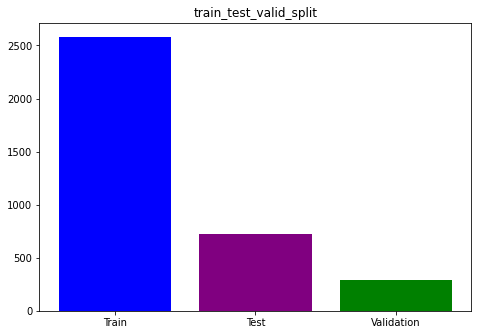

In [ ]:
fig = plt.figure()
ax = fig.add_axes([0,0,1,1])
separations = ['Train', 'Test', 'Validation']
images = [x_train.shape[0], x_test.shape[0], x_validate.shape[0]]
ax.bar(separations, images, color=['blue', 'purple', 'green'])
plt.savefig('train_test_valid_split.png')
plt.title('train_test_valid_split')
plt.show()

--------------------------------------------

## ImageDataGenerator and ReduceLROnPlateau

In [ ]:
datagen = ImageDataGenerator(
    featurewise_center = True,
    featurewise_std_normalization = True,
    rotation_range = 20,
    width_shift_range = 0.2,
    height_shift_range = 0.2,
    horizontal_flip = True,
    validation_split = 0.2)

datagen.fit(x_train)

learning_rate_reduction = ReduceLROnPlateau(monitor = 'val_accuracy',
                                            patience = 3,
                                            verbose = 1,
                                            factor = 0.3,
                                            min_lr = 0.00001)

## EfficientNetV2L with 3 dense layer 50 epochs

In [ ]:
base_model = tf.keras.applications.EfficientNetV2L(
    weights = 'imagenet',
    input_shape = (image_shape, image_shape, 3),
    include_top = False)

base_model.trainable = True

473186304/473176280 [==============================] - 2s 0us/step


In [ ]:
inputs = keras.Input(shape=(image_shape, image_shape, 3))
x = base_model(inputs, training=True)
x = keras.layers.GlobalAveragePooling2D()(x)

dense_1 = Dense(2048, activation='relu')(x)
dense_2 = Dense(512, activation='relu')(dense_1)
dense_3 = Dense(256, activation='relu')(dense_2)
output = Dense(5, activation='softmax')(dense_3)
model = keras.Model(inputs, output)

# summarize model
model.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 efficientnetv2-l (Functiona  (None, 7, 7, 1280)       117746848 
 l)                                                              
                                                                 
 global_average_pooling2d (G  (None, 1280)             0         
 lobalAveragePooling2D)                                          
                                                                 
 dense (Dense)               (None, 2048)              2623488   
                                                                 
 dense_1 (Dense)             (None, 512)               1049088   
                                                                 
 dense_2 (Dense)             (None, 256)               131328

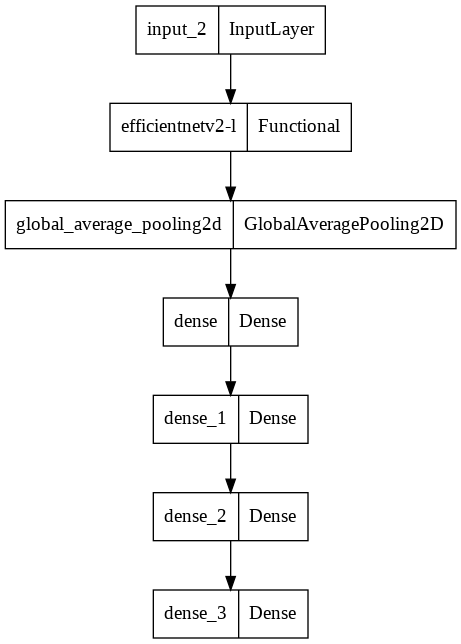

In [ ]:
tf.keras.utils.plot_model(
    model,
    to_file="model.png",
    show_shapes=False,
    show_dtype=False,
    show_layer_names=True,
    rankdir="TB",
    expand_nested=False,
    dpi=96,
    layer_range=None,
    show_layer_activations=False,
)

In [ ]:
model.compile(optimizer= tf.keras.optimizers.Adam(learning_rate=0.001,
                                                  beta_1=0.9,
                                                  beta_2=0.999,
                                                  amsgrad=False),
              loss='categorical_crossentropy',
              metrics = ['accuracy'])

epochs = 50
batch_size = 42

history = model.fit(datagen.flow(x_train, y_train, batch_size = batch_size),
                    epochs = epochs, validation_data = (x_validate, y_validate),
                    verbose = 1, steps_per_epoch = x_train.shape[0] // batch_size,
                    callbacks=[learning_rate_reduction])

In [ ]:
loss, accuracy = model.evaluate(x_test, y_test, verbose=1)
loss_v, accuracy_v = model.evaluate(x_validate, y_validate, verbose=1)
print("Validation: accuracy = %f  ;  loss_v = %f" % (accuracy_v, loss_v))
print("Test: accuracy = %f  ;  loss = %f" % (accuracy, loss))

In [ ]:
fig, ax1 = plt.subplots(figsize= (15, 10) )
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')
#plt.savefig("Model_accuracy_InceptionV3.png")
plt.show()

fig, ax1 = plt.subplots(figsize= (15, 10) )
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')
#plt.savefig("Model_loss_InceptionV3.png")
plt.show()

In [ ]:
Y_pred = model.predict(x_validate)
Y_pred_classes = np.argmax(Y_pred,axis = 1)
Y_true = np.argmax(y_validate,axis = 1)
cm = confusion_matrix(Y_true, Y_pred_classes)

label = pd.unique(meta_df['diag'])
f,ax = plt.subplots(figsize=(18, 18))
ax = sns.heatmap(cm, xticklabels=label, yticklabels=label, linewidths=.5 , cbar=False , fmt="d" , annot=True)
#plt.savefig("confusion_matrix_InceptionV3.png")
plt.show()

In [ ]:
label_error = 1 - np.diag(cm) / np.sum(cm, axis=1)
plt.figure(figsize=(25,10))
plt.bar(label,label_error)
plt.xlabel('True Label')
plt.ylabel('Classified incorrectly')
#plt.savefig("Classified_incorrectly_InceptionV3.png")

## Xception with 3 dense layer 50 epochs

In [ ]:
base_model = tf.keras.applications.Xception(
    weights = 'imagenet',
    input_shape = (image_shape, image_shape, 3),
    include_top = False)

base_model.trainable = True

83697664/83683744 [==============================] - 2s 0us/step


In [ ]:
inputs = keras.Input(shape=(image_shape, image_shape, 3))
x = base_model(inputs, training=True)
x = keras.layers.GlobalAveragePooling2D()(x)

dense_1 = Dense(2048, activation='relu')(x)
dense_2 = Dense(512, activation='relu')(dense_1)
dense_3 = Dense(256, activation='relu')(dense_2)
output = Dense(5, activation='softmax')(dense_3)
model = keras.Model(inputs, output)

# summarize model
model.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 xception (Functional)       (None, 7, 7, 2048)        20861480  
                                                                 
 global_average_pooling2d (G  (None, 2048)             0         
 lobalAveragePooling2D)                                          
                                                                 
 dense (Dense)               (None, 2048)              4196352   
                                                                 
 dense_1 (Dense)             (None, 512)               1049088   
                                                                 
 dense_2 (Dense)             (None, 256)               131328    
                                                             

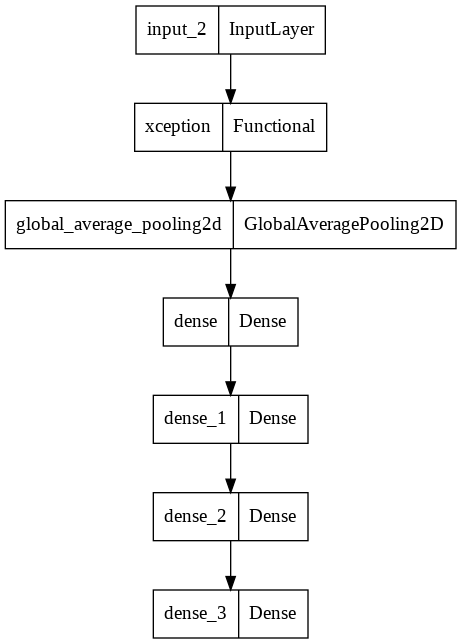

In [ ]:
tf.keras.utils.plot_model(
    model,
    to_file="model.png",
    show_shapes=False,
    show_dtype=False,
    show_layer_names=True,
    rankdir="TB",
    expand_nested=False,
    dpi=96,
    layer_range=None,
    show_layer_activations=False,
)

In [ ]:
model.compile(optimizer= tf.keras.optimizers.Adam(learning_rate=0.001,
                                                  beta_1=0.9,
                                                  beta_2=0.999,
                                                  amsgrad=False),
              loss='categorical_crossentropy',
              metrics = ['accuracy'])

epochs = 50
batch_size = 20

history = model.fit(datagen.flow(x_train, y_train, batch_size = batch_size),
                    epochs = epochs, validation_data = (x_validate, y_validate),
                    verbose = 1, steps_per_epoch = x_train.shape[0] // batch_size,
                    callbacks=[learning_rate_reduction])

Epoch 1/50
129/129 [==============================] - 88s 440ms/step - loss: 1.5680 - accuracy: 0.2832 - val_loss: 1.5696 - val_accuracy: 0.2708 - lr: 0.0010
Epoch 2/50
129/129 [==============================] - 52s 400ms/step - loss: 1.5490 - accuracy: 0.2890 - val_loss: 1.5407 - val_accuracy: 0.2604 - lr: 0.0010
Epoch 3/50
129/129 [==============================] - 52s 402ms/step - loss: 1.5318 - accuracy: 0.2832 - val_loss: 1.5439 - val_accuracy: 0.2917 - lr: 0.0010
Epoch 4/50
129/129 [==============================] - 54s 414ms/step - loss: 1.4823 - accuracy: 0.3011 - val_loss: 1.4915 - val_accuracy: 0.3264 - lr: 0.0010
Epoch 5/50
129/129 [==============================] - 52s 403ms/step - loss: 1.4731 - accuracy: 0.3303 - val_loss: 1.4649 - val_accuracy: 0.2882 - lr: 0.0010
Epoch 6/50
129/129 [==============================] - 53s 408ms/step - loss: 1.4098 - accuracy: 0.3779 - val_loss: 1.3874 - val_accuracy: 0.3750 - lr: 0.0010
Epoch 7/50
129/129 [==============================] 

In [ ]:
loss, accuracy = model.evaluate(x_test, y_test, verbose=1)
loss_v, accuracy_v = model.evaluate(x_validate, y_validate, verbose=1)
print("Validation: accuracy = %f  ;  loss_v = %f" % (accuracy_v, loss_v))
print("Test: accuracy = %f  ;  loss = %f" % (accuracy, loss))

9/9 [==============================] - 1s 144ms/step - loss: 0.2731 - accuracy: 0.9097
Validation: accuracy = 0.909722  ;  loss_v = 0.273097
Test: accuracy = 0.890125  ;  loss = 0.350527


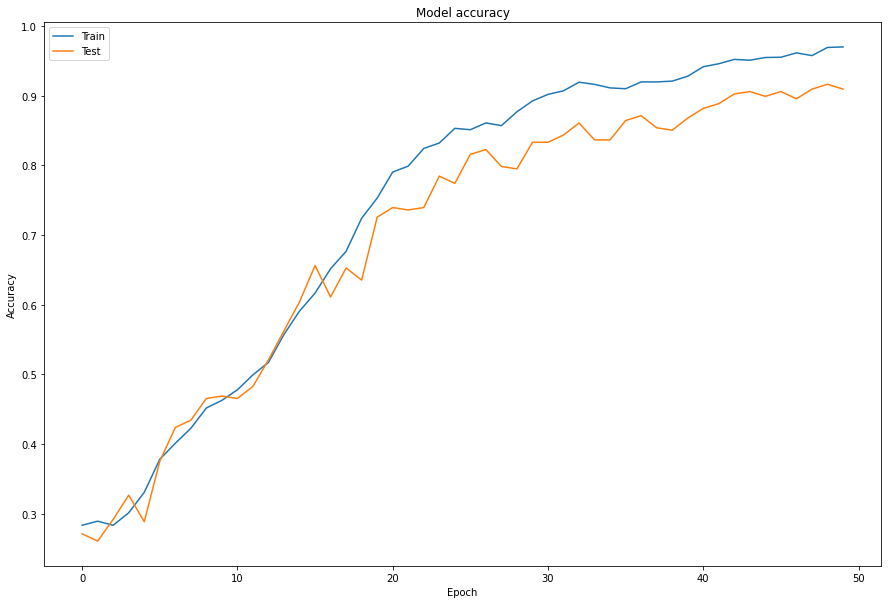

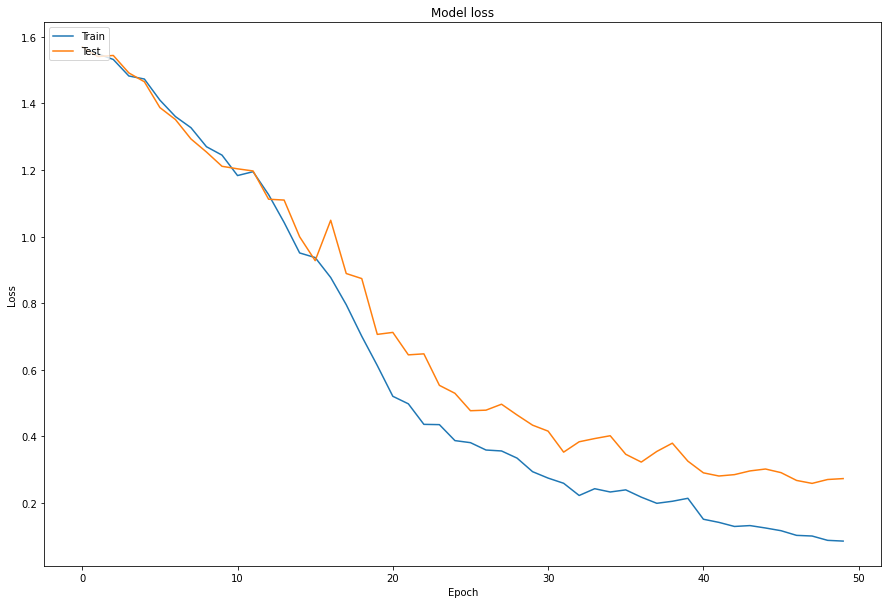

In [ ]:
fig, ax1 = plt.subplots(figsize= (15, 10) )
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')
#plt.savefig("Model_accuracy_InceptionV3.png")
plt.show()

fig, ax1 = plt.subplots(figsize= (15, 10) )
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')
#plt.savefig("Model_loss_InceptionV3.png")
plt.show()

In [ ]:
Y_pred = model.predict(x_validate)
Y_pred_classes = np.argmax(Y_pred,axis = 1)
Y_true = np.argmax(y_validate,axis = 1)
cm = confusion_matrix(Y_true, Y_pred_classes)

label = pd.unique(meta_df['diag'])
f,ax = plt.subplots(figsize=(18, 18))
ax = sns.heatmap(cm, xticklabels=label, yticklabels=label, linewidths=.5 , cbar=False , fmt="d" , annot=True, cmap="YlGnBu")
#plt.savefig("confusion_matrix_InceptionV3.png")
plt.show()

Text(0, 0.5, 'Classified incorrectly')

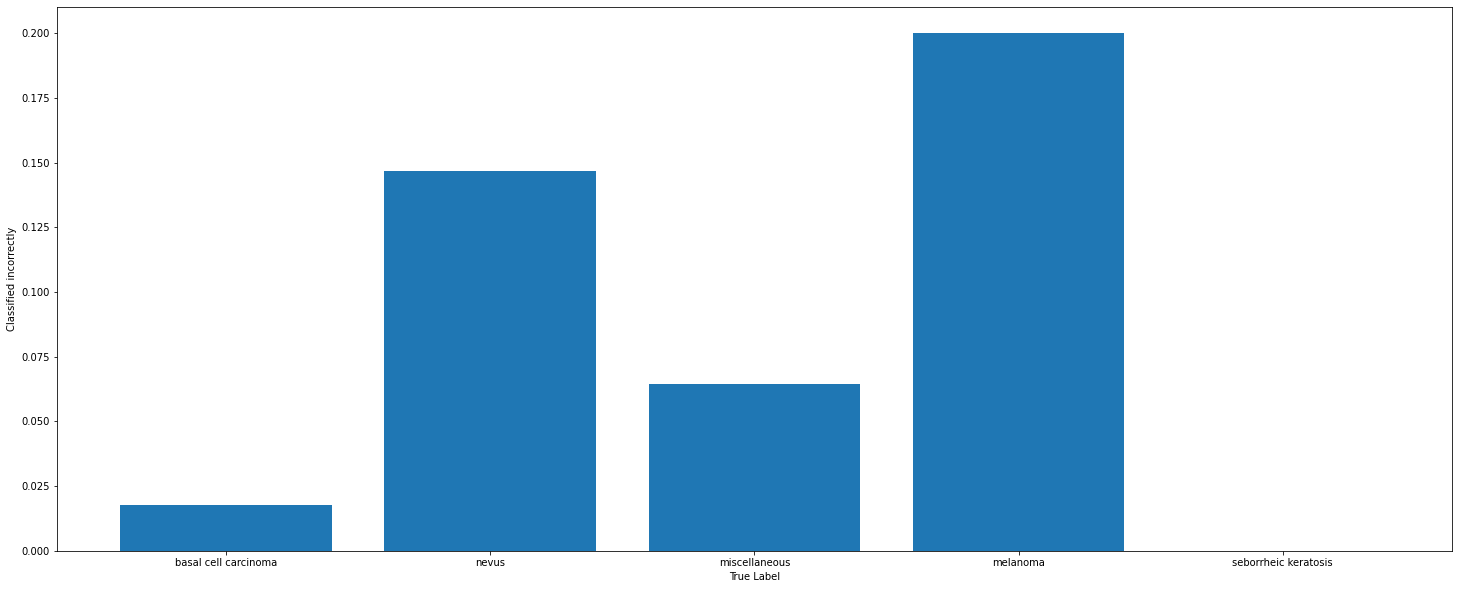

In [ ]:
label_error = 1 - np.diag(cm) / np.sum(cm, axis=1)
plt.figure(figsize=(25,10))
plt.bar(label,label_error)
plt.xlabel('True Label')
plt.ylabel('Classified incorrectly')
#plt.savefig("Classified_incorrectly_InceptionV3.png")